# FM24 Girona Squad Analysis
Goals vs xG and Wage vs Contribution. Data: squad table exported from my own Football Manager 24 save (Girona, January 2032, mid-season).

**How to run in Colab:** upload `Untitled.html` to the Files sidebar, then run the cells from top to bottom.

## 1. Setup

In [17]:
!pip install -q adjustText

import re
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO
from adjustText import adjust_text

FILE_PATH = "/content/Girona_Analysis.html"   # change if your file is elsewhere
MIN_MINUTES = 500

## 2. Load and clean the data

In [18]:
with open(FILE_PATH, encoding="utf-8") as f:
    df = pd.read_html(StringIO(f.read()), header=0, thousands=",")[0]

# Fix garbled names (e.g. "VÃ­ctor" -> "Víctor"); safe if names are already correct
def fix_name(s):
    try:
        return s.encode("cp1252").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

df["Player"] = df["Player"].str.replace(" - Pick Player", "", regex=False).apply(fix_name)

# Drop columns that are empty or not needed
df = df.drop(columns=["Ability", "Potential", "EU National", "Position Selected"], errors="ignore")

# Apps "18 (3)" -> starts and substitute appearances
apps = df["Apps"].astype(str).str.extract(r"(\d+)\s*(?:\((\d+)\))?")
df["Starts"] = apps[0].astype(int)
df["Subs"] = apps[1].fillna(0).astype(int)

# Wage "£75,000 p/w" -> 75000
df["Wage_pw"] = df["Wage"].str.replace(r"[^\d]", "", regex=True).astype(int)

# Pass completion "93%" -> 93.0
df["Pas %"] = df["Pas %"].astype(str).str.replace("%", "").astype(float)

# Transfer value "£54M - £60M" / "£121M" / "£350K" -> midpoint in millions
def parse_value(s):
    nums = re.findall(r"£([\d.]+)([MK])", s)
    vals = [float(n) * (1 if u == "M" else 0.001) for n, u in nums]
    return sum(vals) / len(vals)

df["Value_M"] = df["Transfer Value"].apply(parse_value)

df.head()

,Inf,Player,Position,Age,Nat,Position/Role/Duty,Morale,Overall Risk,Apps,Gls,...,Wor,Tea,Cnt,Dec,Cmp,Tec,Starts,Subs,Wage_pw,Value_M
0,NaN,Niklas Hedl,GK,30,AUT,SK - Support,Superb,Normal injury risk,23,0,...,17,12,13,12,10,5,23,0,75000,57.0
1,Prm,Stefano Ollanu,D (R),20,ITA,D (R),Quite Good,Normal injury risk,7 (5),0,...,12,12,13,16,10,12,7,5,40000,56.0
2,NaN,Leny Yoro,D (C),26,FRA,BPD - Defend,Exceptional,Normal injury risk,23,10,...,14,12,15,15,13,12,23,0,53000,49.5
3,Tgt,Anthony Lechevallier,D (RC),23,FRA,D (C),Excellent,Normal injury risk,18 (2),0,...,11,12,14,12,12,14,18,2,33500,36.5
4,Wnt,Michał Karbownik,D/WB (RL),30,POL,WB - Support,Excellent,Normal injury risk,18 (3),1,...,13,15,12,13,13,13,18,3,120000,35.0


## 3. Derived metrics

In [19]:
df["xG_diff"] = df["Gls"] - df["xG"]
df["G_per90"] = df["Gls"] / df["Mins"] * 90
df["xG_per90"] = df["xG"] / df["Mins"] * 90
df["GA_per90"] = (df["Gls"] + df["Ast"]) / df["Mins"] * 90

print(f"{len(df)} players in the export")
df[["Player", "Mins", "Gls", "Ast", "xG", "xG_diff", "GA_per90", "Wage_pw"]].head()

21 players in the export


,Player,Mins,Gls,Ast,xG,xG_diff,GA_per90,Wage_pw
0,Niklas Hedl,2070,0,0,0.00,0.00,0.000000,75000
1,Stefano Ollanu,698,0,1,0.41,-0.41,0.128940,40000
2,Leny Yoro,2032,10,2,4.47,5.53,0.531496,53000
3,Anthony Lechevallier,1633,0,0,1.07,-1.07,0.000000,33500
4,Michał Karbownik,1553,1,9,1.12,-0.12,0.579524,120000


## 4. Filter and position groups
Only players with at least 500 minutes are kept, and goalkeepers are excluded from the charts. Position groups come from the first listed position, with manual corrections for a few players.

In [20]:
def group(pos):
    first = pos.split(",")[0].strip()
    if first.startswith("GK"):
        return "Goalkeeper"
    if first.startswith(("ST", "AM")):
        return "Forward"
    if first.startswith(("M", "DM")):
        return "Midfielder"
    return "Defender"

manual = {"Georgi Nikolov": "Midfielder", "Mikey Moore": "Forward", "Lucas Román": "Forward"}
colors = {"Goalkeeper": "gray", "Defender": "tab:blue", "Midfielder": "tab:green", "Forward": "tab:red"}

reg = df[df["Mins"] >= MIN_MINUTES].copy()
reg["Group"] = reg["Position"].apply(group)
reg["Group"] = reg.apply(lambda r: manual.get(r["Player"], r["Group"]), axis=1)
outfield = reg[reg["Group"] != "Goalkeeper"]

print(f"{len(reg)} players with {MIN_MINUTES}+ minutes, {len(outfield)} outfield players")

17 players with 500+ minutes, 16 outfield players


## 5. Chart 1: Goals vs xG

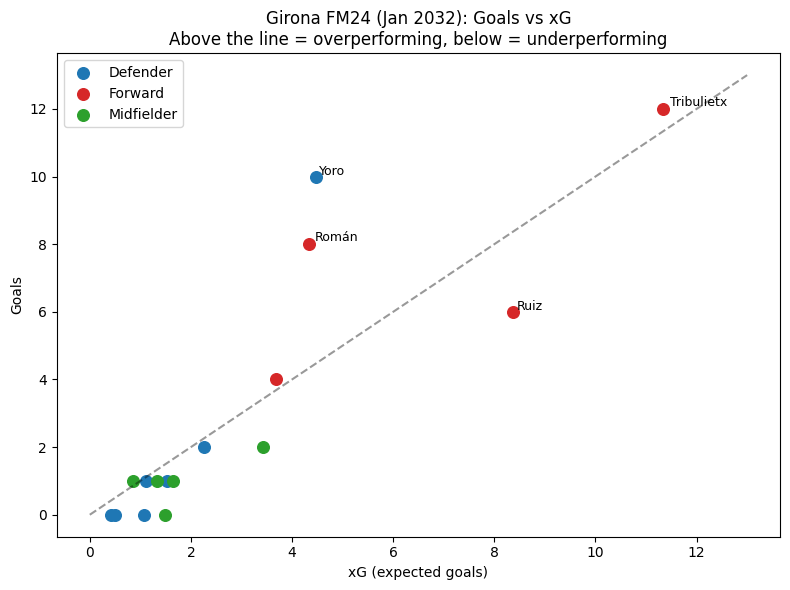

In [21]:
fig, ax = plt.subplots(figsize=(8, 6))
for g, d in outfield.groupby("Group"):
    ax.scatter(d["xG"], d["Gls"], label=g, color=colors[g], s=70)

mx = max(outfield["xG"].max(), outfield["Gls"].max()) + 1
ax.plot([0, mx], [0, mx], "--", color="black", alpha=0.4)

sel = outfield[(outfield["xG_diff"].abs() >= 2) | (outfield["Gls"] >= 8)]
texts = [ax.text(r["xG"], r["Gls"], r["Player"].split()[-1], fontsize=9)
         for _, r in sel.iterrows()]
_ = adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

ax.set_xlabel("xG (expected goals)")
ax.set_ylabel("Goals")
ax.set_title("Girona FM24 (Jan 2032): Goals vs xG\nAbove the line = overperforming, below = underperforming")
ax.legend()
plt.tight_layout()
plt.savefig("chart_goal_vs_xg.png", dpi=200)
plt.show()

## 6. Chart 2: Wage vs Contribution

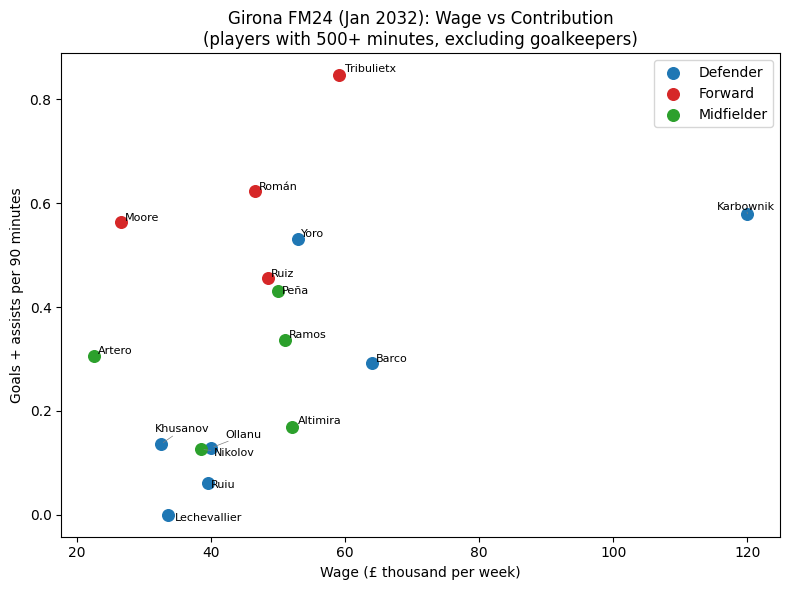

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
for g, d in outfield.groupby("Group"):
    ax.scatter(d["Wage_pw"] / 1000, d["GA_per90"], label=g, color=colors[g], s=70)

texts = [ax.text(r["Wage_pw"] / 1000, r["GA_per90"], r["Player"].split()[-1], fontsize=8)
         for _, r in outfield.iterrows()]
_ = adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

ax.set_xlabel("Wage (£ thousand per week)")
ax.set_ylabel("Goals + assists per 90 minutes")
ax.set_title("Girona FM24 (Jan 2032): Wage vs Contribution\n(players with 500+ minutes, excluding goalkeepers)")
ax.legend()
plt.tight_layout()
plt.savefig("chart_wages_vs_kontribution.png", dpi=200)
plt.show()

## 7. Save the cleaned data

In [23]:
df.to_csv("girona_squad_clean.csv", index=False, encoding="utf-8-sig")
print("Saved girona_squad_clean.csv")

Saved girona_squad_clean.csv


## Limitations
- Half a season of data, so large gaps (e.g. Yoro's goals vs xG) may be variance or set-piece goals.
- Goals + assists per 90 is unfair for defenders and defensive midfielders.
- Position groups are approximate.